# Descriptive and Inferential Statistics

**AI Mathematics · 3. Probability and Statistics**

Summarize data, quantify variability, understand correlation, and distinguish descriptive estimates from statistical inference.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Calculate mean, median, variance, standard deviation, covariance, and correlation.
- Understand estimators and confidence intervals.
- Interpret hypothesis tests without overstating p-values.

In [1]:
import numpy as np

## 1. Center and spread
The mean is sensitive to outliers; the median is more robust. Population variance divides by \(n\), while the common unbiased sample variance estimator divides by \(n-1\). NumPy’s `var` defaults to `ddof=0`; use `ddof=1` for sample variance.

In [2]:
import numpy as np
data = np.array([10.0, 11.0, 12.0, 13.0, 100.0])
print("mean:", data.mean())
print("median:", np.median(data))
print("population variance:", data.var())
print("sample variance:", data.var(ddof=1))
print("sample standard deviation:", data.std(ddof=1))

mean: 29.2
median: 12.0
population variance: 1254.1599999999999
sample variance: 1567.6999999999998
sample standard deviation: 39.594191493197584


## 2. Covariance and correlation
Covariance measures joint variation and depends on units. Correlation standardizes covariance to lie between -1 and 1. Correlation describes linear association; it does not prove causation and may miss nonlinear relationships.

In [3]:
x = np.array([1.0, 2.0, 3.0, 4.0])
y = np.array([2.0, 1.0, 4.0, 3.0])
print("covariance matrix:\n", np.cov(np.vstack([x, y])))
print("correlation matrix:\n", np.corrcoef(np.vstack([x, y])))

covariance matrix:
 [[1.66666667 1.        ]
 [1.         1.66666667]]
correlation matrix:
 [[1.  0.6]
 [0.6 1. ]]


## 3. Estimators and sampling variability
An estimator is a rule for using a sample to estimate a population quantity. Different samples lead to different estimates. The standard error describes the variability of an estimator under repeated sampling; it is not the same as the standard deviation of individual observations.

In [4]:
rng = np.random.default_rng(12)
population = rng.normal(loc=5.0, scale=2.0, size=200_000)
means = [rng.choice(population, size=50, replace=False).mean() for _ in range(1000)]
print("average sample mean:", np.mean(means))
print("standard error estimated from repeated samples:", np.std(means, ddof=1))
print("theoretical standard error approx:", 2.0 / np.sqrt(50))

average sample mean: 5.00429800266486
standard error estimated from repeated samples: 0.2909154349603534
theoretical standard error approx: 0.282842712474619


## 4. Confidence intervals
A 95% confidence procedure produces intervals that cover the fixed parameter in 95% of repeated samples under its assumptions. It does not mean that there is a 95% probability the fixed parameter lies in this one already-computed interval. The familiar normal interval below assumes a known population standard deviation or uses it as an approximation.

In [5]:
sample = np.array([4.8, 5.1, 4.9, 5.3, 4.7, 5.0, 5.2, 4.9])
mean = sample.mean()
se = sample.std(ddof=1) / np.sqrt(len(sample))
# Approximate 95% interval using 1.96; a small-sample t interval uses a larger critical value.
ci = (mean - 1.96*se, mean + 1.96*se)
print("mean:", mean)
print("approximate 95% interval:", ci)

mean: 4.9875
approximate 95% interval: (np.float64(4.846758215159818), np.float64(5.128241784840181))


## 5. Hypothesis tests and p-values
A p-value is the probability, under the null hypothesis and test assumptions, of data at least as extreme as what was observed. It is not the probability that the null hypothesis is true. Statistical significance is not the same as practical importance; report effect sizes and uncertainty too.

In [6]:
from math import erf, sqrt
# Simple illustrative z-test for a known standard error
z = 2.0
def normal_cdf(z):
    return 0.5 * (1 + erf(z / sqrt(2)))
p_two_sided = 2 * (1 - normal_cdf(abs(z)))
print("z statistic:", z)
print("two-sided p-value:", p_two_sided)

z statistic: 2.0
two-sided p-value: 0.04550026389635842


### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: explore a dataset before modeling

`pandas` makes it easy to inspect columns, summarize distributions, and calculate correlations. `seaborn` provides compact statistical plots. Remember that correlation is an association, not proof of causation, and that a correlation matrix can be misleading when there are outliers or nonlinear relationships.

11_descriptive_and_inferential_statistics.ipynb:cell15:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
11_descriptive_and_inferential_statistics.ipynb:cell15:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,feature A,feature B,feature C
count,180.000,180.000,180.000
mean,0.022,-0.007,-0.106
std,1.039,1.112,1.010
min,-2.694,-3.389,-2.590
25%,-0.608,-0.719,-0.829
50%,0.098,0.049,-0.092
75%,0.667,0.715,0.653
max,2.869,3.490,2.122


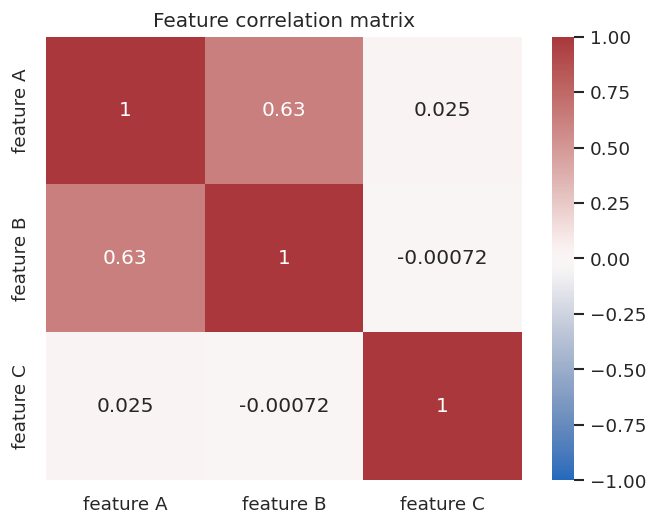

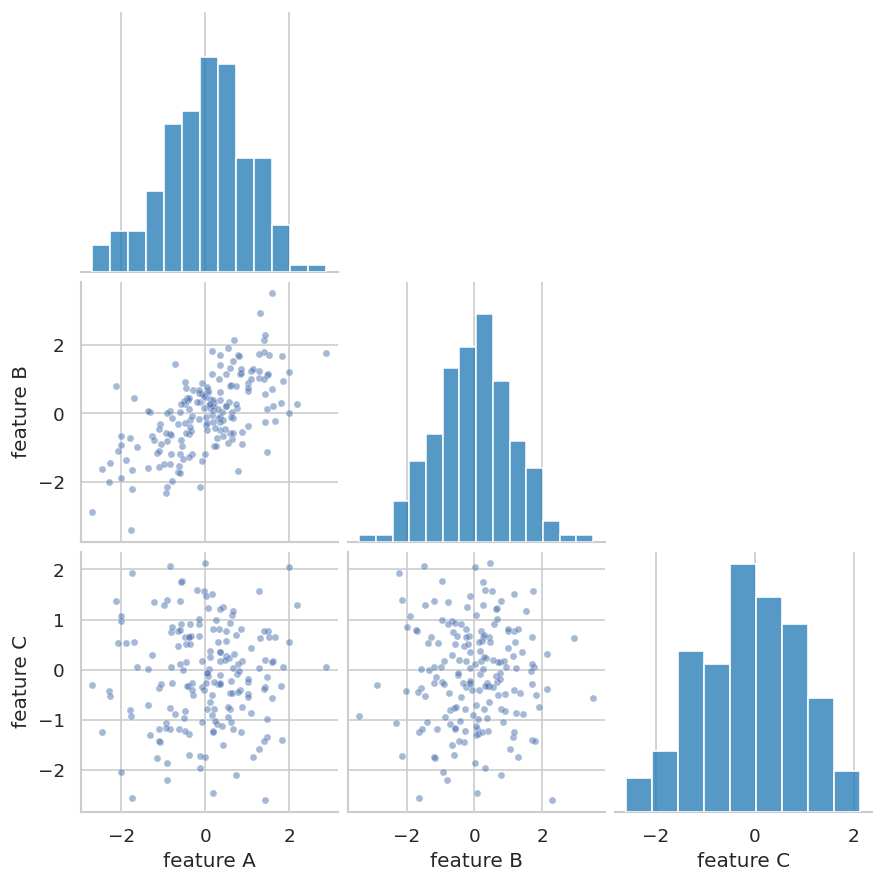

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_stat_rng = np.random.default_rng(202)
viz_stat_x = viz_stat_rng.normal(0, 1, 180)
viz_stat_df = pd.DataFrame({"feature A": viz_stat_x, "feature B": 0.7*viz_stat_x + viz_stat_rng.normal(0, 0.8, 180), "feature C": viz_stat_rng.normal(0, 1, 180)})
display(viz_stat_df.describe().round(3))
sns.heatmap(viz_stat_df.corr(), annot=True, vmin=-1, vmax=1, cmap="vlag", center=0)
plt.title("Feature correlation matrix"); plt.show()
sns.pairplot(viz_stat_df, corner=True, plot_kws={"alpha": 0.5, "s": 18}, diag_kws={"color": "tab:blue"})
plt.show()

### Bootstrap confidence interval for a mean

A bootstrap repeatedly resamples observations with replacement and recalculates a statistic. The percentile interval below approximates uncertainty in the sample mean. Its validity depends on how representative the original sample is and on the sampling assumptions; resampling cannot repair biased data.

sample mean: 0.022
approx. 95% bootstrap interval: [-0.131  0.173]


11_descriptive_and_inferential_statistics.ipynb:cell17:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


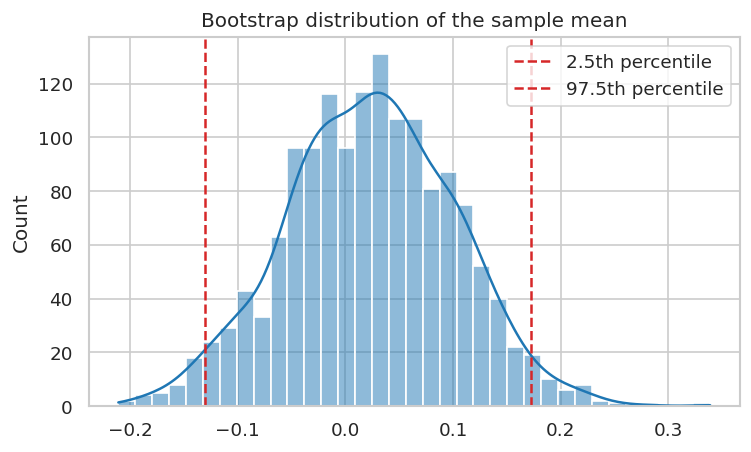

In [8]:
viz_boot_values = viz_stat_df["feature A"].to_numpy()
viz_boot_rng = np.random.default_rng(19)
viz_boot_means = np.array([viz_boot_rng.choice(viz_boot_values, size=len(viz_boot_values), replace=True).mean() for _ in range(1500)])
viz_boot_ci = np.quantile(viz_boot_means, [0.025, 0.975])
print("sample mean:", round(float(viz_boot_values.mean()), 3))
print("approx. 95% bootstrap interval:", np.round(viz_boot_ci, 3))
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(viz_boot_means, bins=35, kde=True, color="tab:blue", ax=ax)
ax.axvline(viz_boot_ci[0], color="tab:red", linestyle="--", label="2.5th percentile")
ax.axvline(viz_boot_ci[1], color="tab:red", linestyle="--", label="97.5th percentile")
ax.legend(); ax.set_title("Bootstrap distribution of the sample mean"); plt.show()

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Compute the median and sample variance for [2, 4, 4, 10].

In [9]:
x = np.array([2.0, 4.0, 4.0, 10.0])
print(np.median(x), x.var(ddof=1))

4.0 12.0


### Exercise 2
Exercise 2: Explain in a code comment what a correlation of -1 indicates.

In [10]:
# A correlation of -1 indicates a perfect negative linear relationship in the observed paired values.

## Key takeaways
- Use robust summaries when outliers may dominate the mean.
- Correlation is association, not causation, and captures only linear relationships.
- Confidence intervals and p-values require assumptions; interpretation should be precise.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.